# Soft Actor-Critic (SAC), from scratch
### Pendulum swing-up for the mechanics, planar-quadrotor hover for the full run

This notebook is the off-policy, continuous-action companion to the **PPO** and **DQN** deep dives. Those lectures
covered an on-policy method (PPO) and a value-based method with a discrete menu of actions (DQN). SAC uses both ideas.
Like DQN it learns a Q-function from a replay buffer. Like PPO it trains a stochastic policy that outputs continuous
actions directly. It also adds a third ingredient: the agent is **paid for staying random**.

**Learning objectives.** By the end you should be able to

1. write down the maximum-entropy objective and explain what the temperature α trades off;
2. derive the three SAC losses (critic, actor, temperature) and implement them in ~60 lines of PyTorch;
3. explain why the actor gradient uses the **reparameterisation trick** and measure how much variance that saves;
4. implement **tanh squashing** with the correct log-probability correction, and recognise the symptoms when it is missing;
5. explain **clipped double-Q** and measure its effect on value bias;
6. compare SAC with its deterministic relatives **DDPG** and **TD3** on precision and actuator chatter;
7. read a SAC training dashboard (entropy, α, saturation, Q) and diagnose the common failures.

**Prerequisites.** The RL quadrotor lecture (MDPs, Q-learning, DQN, policy gradients) and the PPO and DQN deep dives.
PyTorch at the level of `nn.Module`, `optimizer.step()` and `torch.no_grad()`.

**Runtime.** About 25 minutes on 2 CPU cores with `QUICK = False`: 18 pendulum runs (~35 s each) and 18 quadrotor runs (~2 min each),
two at a time. Set `QUICK = True` for one seed per configuration (~11 min). The numbers quoted in the text are for `QUICK = False`.

In [1]:
import sys, platform, time, math, multiprocessing as mp
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.set_num_threads(1)     # one thread per worker -> runs are bit-reproducible
QUICK = False
print("python", platform.python_version(), "| numpy", np.__version__, "| torch", torch.__version__)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

python 3.13.18 | numpy 2.5.3 | torch 2.15.0+cu132


## 1. Two environments

**Pendulum** (Gymnasium `Pendulum-v1` dynamics): one torque action |u| ≤ 2 N·m, observation (cos θ, sin θ, θ̇/8),
20 Hz, 200-step episodes, reward −(θ² + 0.1 θ̇² + 0.001 u²). The motor is too weak to lift the pendulum directly, so the
policy has to pump energy, swing up and then balance. It is small enough that one SAC run takes ~35 s, which makes it
our lab bench for mechanics and ablations.

**Planar quadrotor** (identical to the PPO and DQN deep dives): 0.80 kg, arm 0.17 m, thrust-to-weight 2, 30 ms motor lag,
50 Hz, 250-step episodes. Two actions u ∈ [−1, 1]² set the rotor thrusts T_i = T_hover(1 + u_i). The task is to fly to
(0, 1.5) m and hover. Reward per step is 1 − ‖e‖ − 0.2|θ| − 0.05‖v‖ − 0.02|ω| − 0.05‖Δu‖, and a crash costs −10 and ends the episode.

Both environments are vectorised in NumPy, and both return `final_obs` so that **time-outs can be bootstrapped**.
A time-out is not a terminal state, and we will see what happens if you treat it as one.

In [2]:
class PendulumVec:
    '''Pendulum-v1 dynamics, vectorised. theta = 0 is upright, |torque| <= 2 N m, 20 Hz, 200 steps.
    Action a in [-1, 1] is scaled to torque 2a.  Time-outs are truncations, never terminations.'''
    obs_dim, act_dim, T = 3, 1, 200
    g, m, l, dt, max_speed, max_torque = 10.0, 1.0, 1.0, 0.05, 8.0, 2.0

    def __init__(self, n, seed=0):
        self.n, self.rng = n, np.random.default_rng(seed)
        self.th, self.thd, self.t = np.zeros(n), np.zeros(n), np.zeros(n, int)
        self.reset_idx(np.arange(n))

    def reset_idx(self, idx):
        self.th[idx] = self.rng.uniform(-np.pi, np.pi, len(idx))
        self.thd[idx] = self.rng.uniform(-1, 1, len(idx))
        self.t[idx] = 0

    def obs(self):
        return np.stack([np.cos(self.th), np.sin(self.th), self.thd / 8.0], 1).astype(np.float32)

    def reset(self):
        self.reset_idx(np.arange(self.n)); return self.obs()

    def step(self, a):
        u = np.clip(a[:, 0], -1, 1) * self.max_torque
        thn = ((self.th + np.pi) % (2 * np.pi)) - np.pi
        r = -(thn ** 2 + 0.1 * self.thd ** 2 + 0.001 * u ** 2)
        self.thd = np.clip(self.thd + (3 * self.g / (2 * self.l) * np.sin(self.th)
                                       + 3.0 / (self.m * self.l ** 2) * u) * self.dt,
                           -self.max_speed, self.max_speed)
        self.th = self.th + self.thd * self.dt
        self.t += 1
        term = np.zeros(self.n, bool)
        trunc = self.t >= self.T
        final_obs = self.obs()
        done = np.where(term | trunc)[0]
        if len(done): self.reset_idx(done)
        return self.obs(), r.astype(np.float32), term, trunc, final_obs

In [3]:
class QuadVec:
    '''Planar quadrotor (same model as the PPO and DQN deep dives): 0.80 kg, arm 0.17 m, I 0.006,
    drag 0.10, thrust-to-weight 2, 30 ms first-order motor lag, 50 Hz, 250-step episodes,
    target (0, 1.5).  Action u in [-1,1]^2:  T_i = T_hover (1 + u_i).  Crash = -10 and terminate.'''
    obs_dim, act_dim, T = 9, 2, 250
    m, arm, I, drag, g, dt, tau_m = 0.80, 0.17, 0.006, 0.10, 9.81, 0.02, 0.03
    target = (0.0, 1.5)

    def __init__(self, n, seed=0):
        self.n, self.rng = n, np.random.default_rng(seed)
        self.Th = self.m * self.g / 2
        self.s = np.zeros((n, 8))          # x z th xd zd w T1 T2
        self.u_prev = np.zeros((n, 2)); self.t = np.zeros(n, int)
        self.k_lag = 1 - math.exp(-self.dt / self.tau_m)
        self.reset_idx(np.arange(n))

    def reset_idx(self, idx):
        k = len(idx); R = self.rng
        self.s[idx, 0] = R.uniform(-1.0, 1.0, k)
        self.s[idx, 1] = self.target[1] + R.uniform(-0.8, 0.8, k)
        self.s[idx, 2] = R.uniform(-0.3, 0.3, k)
        self.s[idx, 3:5] = R.uniform(-0.3, 0.3, (k, 2))
        self.s[idx, 5] = R.uniform(-0.5, 0.5, k)
        self.s[idx, 6:8] = self.Th
        self.u_prev[idx] = 0.0; self.t[idx] = 0

    def obs(self):
        x, z, th, xd, zd, w = self.s[:, :6].T
        return np.stack([x - self.target[0], z - self.target[1], np.sin(th), np.cos(th),
                         xd, zd, w / 4.0, self.u_prev[:, 0], self.u_prev[:, 1]], 1).astype(np.float32)

    def reset(self):
        self.reset_idx(np.arange(self.n)); return self.obs()

    def step(self, a):
        u = np.clip(a, -1, 1)
        s = self.s
        Tc = self.Th * (1 + u)
        s[:, 6:8] += self.k_lag * (Tc - s[:, 6:8])
        F_ = s[:, 6] + s[:, 7]; tq = (s[:, 7] - s[:, 6]) * self.arm
        th = s[:, 2]
        xdd = (-F_ * np.sin(th) - self.drag * s[:, 3]) / self.m
        zdd = (F_ * np.cos(th) - self.drag * s[:, 4]) / self.m - self.g
        wd = tq / self.I
        s[:, 3] += xdd * self.dt; s[:, 4] += zdd * self.dt; s[:, 5] += wd * self.dt
        s[:, 0] += s[:, 3] * self.dt; s[:, 1] += s[:, 4] * self.dt; s[:, 2] += s[:, 5] * self.dt
        ex, ez = s[:, 0] - self.target[0], s[:, 1] - self.target[1]
        du = np.linalg.norm(u - self.u_prev, axis=1)
        r = (1 - np.hypot(ex, ez) - 0.2 * np.abs(s[:, 2]) - 0.05 * np.hypot(s[:, 3], s[:, 4])
             - 0.02 * np.abs(s[:, 5]) - 0.05 * du)
        self.u_prev = u.copy(); self.t += 1
        crash = (s[:, 1] < 0.05) | (np.abs(ex) > 2.5) | (np.abs(s[:, 2]) > 1.4) | (np.abs(ez) > 2.0)
        r = np.where(crash, -10.0, r)
        term, trunc = crash, (self.t >= self.T) & ~crash
        final_obs = self.obs()
        done = np.where(term | trunc)[0]
        if len(done): self.reset_idx(done)
        return self.obs(), r.astype(np.float32), term, trunc, final_obs

def pd_policy(o):
    '''Cascaded PD baseline that knows the nominal model (kp 4, kd 3, kp_th 60, kd_th 12).'''
    Q = QuadVec
    ex, ez, sn, cs, xd, zd, w = o[:, 0], o[:, 1], o[:, 2], o[:, 3], o[:, 4], o[:, 5], o[:, 6] * 4
    th = np.arctan2(sn, cs)
    ax, az = -4 * ex - 3 * xd, -4 * ez - 3 * zd
    th_des = np.clip(-ax / Q.g, -0.5, 0.5)
    Fz = Q.m * (Q.g + az) / np.maximum(np.cos(th), 0.3)
    tq = Q.I * (60 * (th_des - th) - 12 * w)
    Th = Q.m * Q.g / 2
    T1, T2 = Fz / 2 - tq / (2 * Q.arm), Fz / 2 + tq / (2 * Q.arm)
    return np.clip(np.stack([T1 / Th - 1, T2 / Th - 1], 1), -1, 1)

def make_env(name, n, seed):
    return {"pendulum": PendulumVec, "quad": QuadVec}[name](n, seed)

Before any learning, sanity-check the environment with two policies we understand. A controller that holds hover thrust
(u = 0) should almost always crash, because it cannot correct the initial tilt, and a random one should crash every time. A cascaded PD controller that knows the nominal model
must fly well. If either check fails, the bug is in the environment and no RL algorithm will fix it.

In [4]:
def evaluate(agent, env_name, n_eps=10, seed=12345, deterministic=True, record=False):
    '''Run n_eps full episodes in parallel; return mean return and (quad) precision metrics.'''
    env = make_env(env_name, n_eps, seed); o = env.reset()
    ret, alive = np.zeros(n_eps), np.ones(n_eps, bool)
    crashed = np.zeros(n_eps, bool); errs, dus, traj = [], [], []
    u_prev = np.zeros((n_eps, env.act_dim))
    for t in range(env.T):
        a = agent(o) if callable(agent) else agent.act(o, deterministic)
        if record: traj.append((o.copy(), a.copy()))
        o2, r, term, trunc, fo = env.step(a)
        ret += r * alive
        if env_name == "quad":
            errs.append(np.hypot(fo[:, 0], fo[:, 1])); dus.append(np.linalg.norm(a - u_prev, axis=1))
        u_prev = a
        crashed |= term & alive; alive &= ~(term | trunc); o = o2
        if not alive.any(): break
    out = {"return": float(ret.mean())}
    if env_name == "quad":
        E = np.array(errs); D = np.array(dus)
        out.update(crash=float(crashed.mean()),
                   final_err_cm=float(100 * E[-50:].mean()) if len(E) >= 50 else float("nan"),
                   chatter=float(D[1:].mean() * 50))         # |du| per second
    if record: out["traj"] = traj
    return out

In [5]:
rng = np.random.default_rng(0)
for name, pol in [("zero thrust change", lambda o: np.zeros((len(o), 2))),
                  ("random", lambda o: rng.uniform(-1, 1, (len(o), 2))),
                  ("cascaded PD", pd_policy)]:
    ev = evaluate(pol, "quad", 50, seed=999)
    err = f"{ev['final_err_cm']:7.2f} cm" if np.isfinite(ev["final_err_cm"]) else "   (all crashed before 1 s)"
    print(f"{name:20s} return {ev['return']:7.1f}  crash {100*ev['crash']:5.1f} %  hover error {err}")

zero thrust change   return   -28.6  crash  98.0 %  hover error  106.03 cm
random               return   -11.0  crash 100.0 %  hover error   76.05 cm
cascaded PD          return   216.9  crash   0.0 %  hover error    0.02 cm


The PD controller scores 217 with a hover error of 0.02 cm. Keep that
number in mind: it is the bar a learned controller is measured against. The PD controller has an unfair advantage, though:
it was designed from the model. SAC will see only rewards.

## 2. The maximum-entropy objective

Standard RL maximises the expected discounted return. SAC (Haarnoja et al., 2018) maximises return **plus entropy**:

$$J(\pi) = \mathbb{E}_{\pi}\Big[\sum_t \gamma^t \big( r(s_t,a_t) + \alpha\, \mathcal{H}(\pi(\cdot\mid s_t)) \big)\Big],
\qquad \mathcal{H}(\pi(\cdot\mid s)) = -\mathbb{E}_{a\sim\pi}[\log \pi(a\mid s)] .$$

The **temperature** α is the exchange rate between reward and randomness. Three consequences follow.

* **Exploration is built into the objective.** It is not bolted on as ε-greedy or added noise. The policy stays random
  where that costs little reward and becomes sharp where precision pays.
* **The optimal policy is a Boltzmann distribution.** For one state with action values Q(a), the maximiser of
  E[Q] + αH is π(a) ∝ exp(Q(a)/α). As α → 0 this becomes the greedy argmax; as α → ∞ it becomes uniform.
* **Robust optima are preferred.** A wide plateau of good actions carries more probability mass than a needle-sharp peak
  of slightly higher value. For a controller this means "pick the action region that still works when you get it a
  bit wrong".

The cell below makes the third point concrete with a one-step landscape: a narrow peak of height 1.0 and a wide
plateau of height 0.85.

In [6]:
A_GRID = np.linspace(-1, 1, 801)

def toy_q(a):
    '''A one-step action landscape with two good actions: a tall narrow peak at -0.55
    and a slightly lower but wide plateau at +0.45.'''
    return 1.0 * np.exp(-(a + 0.55) ** 2 / (2 * 0.06 ** 2)) + 0.85 * np.exp(-(a - 0.45) ** 2 / (2 * 0.22 ** 2))

def boltzmann(alpha, a=A_GRID):
    '''Max-entropy optimal policy pi(a) ~ exp(Q(a)/alpha) on [-1, 1]; returns pi, entropy, soft value.'''
    q = toy_q(a); da = a[1] - a[0]
    z = q / alpha; zmax = z.max()
    w = np.exp(z - zmax); Zn = w.sum() * da
    pi = w / Zn
    H = -(pi * np.log(pi + 1e-300)).sum() * da
    V = alpha * (zmax + np.log(Zn))        # soft value  alpha log integral exp(Q/alpha)
    mass_wide = pi[a > 0].sum() * da
    return pi, H, V, mass_wide

 alpha   entropy H   P(wide plateau)
  0.02      -3.32       0.002
  0.10      -1.09       0.472
  0.30       0.14       0.656
  1.00       0.64       0.570


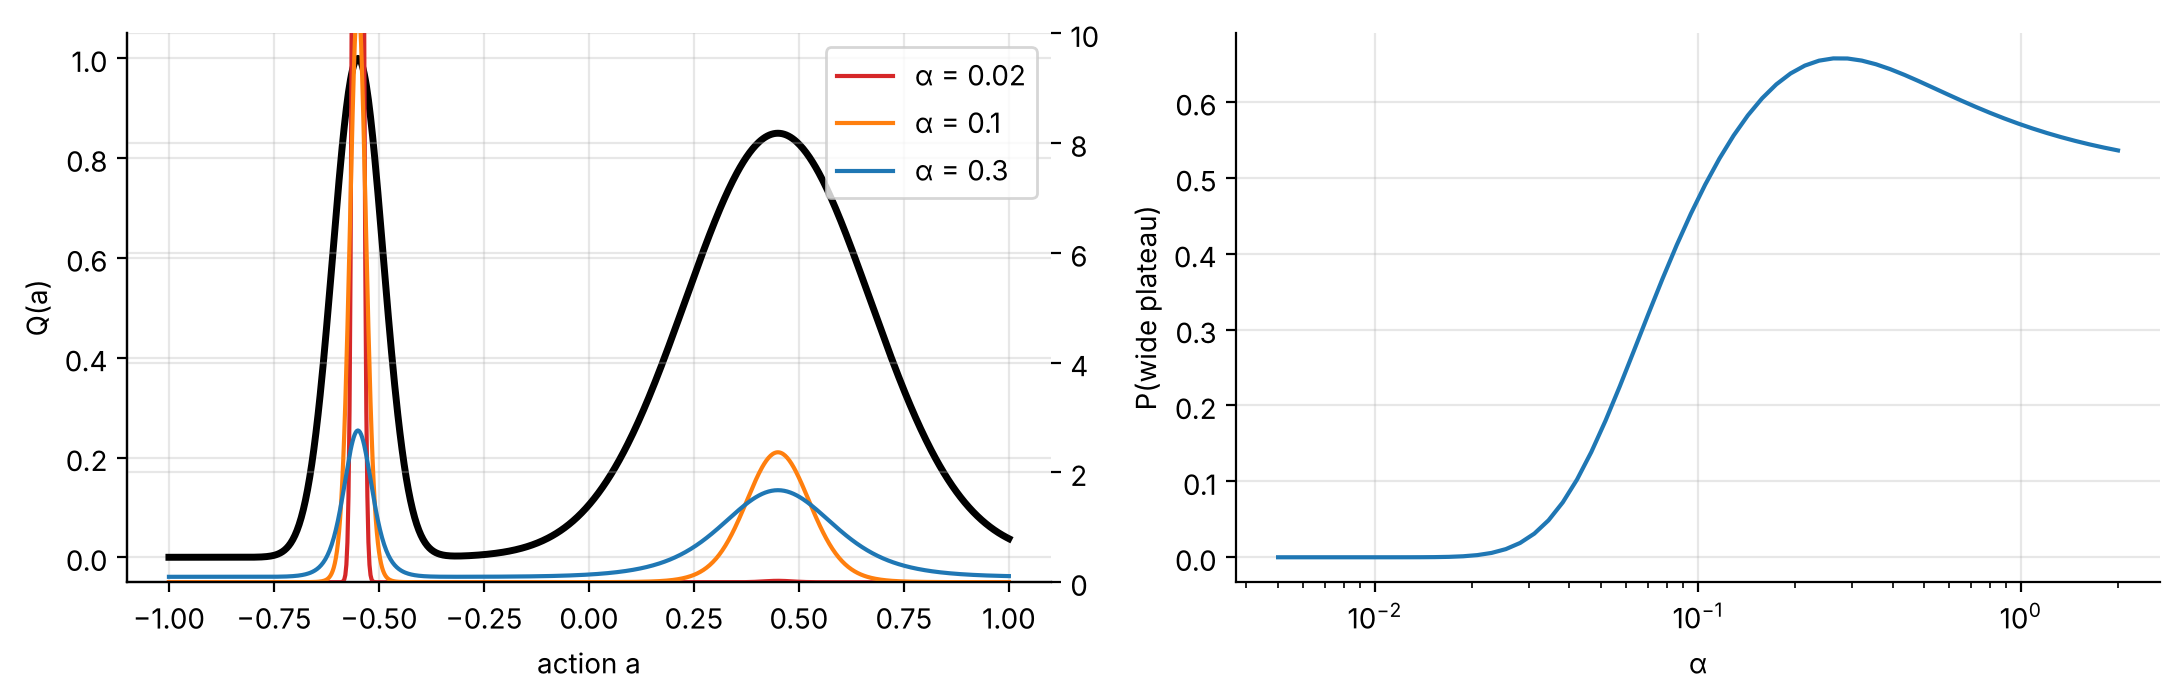

In [7]:
print(" alpha   entropy H   P(wide plateau)")
for al in [0.02, 0.1, 0.3, 1.0]:
    pi, H, V, m = boltzmann(al)
    print(f"{al:6.2f}   {H:8.2f}    {m:8.3f}")

fig, ax = plt.subplots(1, 2)
ax[0].plot(A_GRID, toy_q(A_GRID), "k", lw=2.5, label="Q(a)")
axb = ax[0].twinx()
for al, c in [(0.02, "tab:red"), (0.1, "tab:orange"), (0.3, "tab:blue")]:
    axb.plot(A_GRID, boltzmann(al)[0], c=c, label=f"α = {al}")
axb.set_ylim(0, 10); ax[0].set_xlabel("action a"); ax[0].set_ylabel("Q(a)"); axb.legend(loc="upper right")
als = np.logspace(-2.3, 0.3, 60)
ax[1].semilogx(als, [boltzmann(a)[3] for a in als]); ax[1].set_xlabel("α"); ax[1].set_ylabel("P(wide plateau)")
plt.tight_layout(); plt.show()

At α = 0.02 the policy puts 0.2 % of its mass on the plateau, so it is essentially
greedy. At α = 0.3 it puts 66 % there, even though the plateau's best value is lower.
At very large α the policy approaches uniform, and the plateau share falls back towards its share of the action interval.

> **Pitfall.** "Entropy" here is the *differential* entropy of a continuous density. It can be negative: a Gaussian with σ = 0.1
> has entropy ≈ −0.88 nats. A negative entropy target is normal, not a bug.

## 3. From the objective to three losses

Adding entropy to the return changes the Bellman equation. The **soft** state value includes the entropy bonus:

$$V(s) = \mathbb{E}_{a\sim\pi}\big[Q(s,a) - \alpha \log\pi(a\mid s)\big], \qquad
Q(s,a) = r + \gamma\,(1-d)\,V(s').$$

SAC learns three things from mini-batches (s, a, r, s′, d) drawn from a replay buffer.

| what | loss | note |
|---|---|---|
| **twin critics** Q₁, Q₂ | $\big(Q_i(s,a) - y\big)^2$, &nbsp; $y = r + \gamma(1-d)\big[\min_j \bar Q_j(s',\tilde a') - \alpha\log\pi(\tilde a'\mid s')\big]$, &nbsp; $\tilde a' \sim \pi(\cdot\mid s')$ | fresh action at s′; target critics $\bar Q$ updated by Polyak averaging, τ = 0.005 |
| **actor** π | $\mathbb{E}_{s}\big[\alpha \log\pi(\tilde a\mid s) - \min_j Q_j(s,\tilde a)\big]$, &nbsp; $\tilde a = \tanh(\mu(s) + \sigma(s)\,\varepsilon)$ | gradient flows *through* the sampled action (reparameterisation) |
| **temperature** α | $-\log\alpha\,\big(\log\pi(\tilde a\mid s) + \bar{\mathcal H}\big)$ | drives the entropy towards a target $\bar{\mathcal H} = -\dim(\mathcal A)$ |

Compare the family:

| | DDPG (2016) | TD3 (2018) | SAC (2018) |
|---|---|---|---|
| policy | deterministic | deterministic | **stochastic Gaussian + tanh** |
| exploration | added noise | added noise | **in the objective** |
| critics | one | **two, take the min** | **two, take the min** |
| target policy | target actor | target actor + smoothing noise | **current actor, sampled** |
| actor update | every step | every 2nd step | every step |
| extra knob | — | — | **α, tuned automatically** |

Two reading notes. First, the critic target uses the *current* stochastic policy at s′, so SAC needs no target actor.
Second, the actor's objective is "make the critics happy, but pay α per nat of certainty". The α update is a
Lagrangian dual step: if the entropy is below target, α grows; if above, α shrinks.

## 4. Why the actor gradient uses the reparameterisation trick

The actor loss is an expectation over actions sampled from the policy. There are two ways to differentiate it with
respect to the policy mean μ.

* **Score function** (REINFORCE, as in PPO): $\nabla_\mu \mathbb{E}[Q(a)] = \mathbb{E}[Q(a)\,\nabla_\mu \log\pi(a)]$.
  It needs only the *value* Q(a), so it works for any Q, but its variance is high.
* **Reparameterisation**: write $a = \mu + \sigma\varepsilon$ with $\varepsilon\sim\mathcal N(0,1)$, so
  $\nabla_\mu \mathbb{E}[Q(a)] = \mathbb{E}[\nabla_a Q(a)]$. It needs the *slope* of Q, which a differentiable critic gives us for free.

Take a toy case with a known answer: Q(a) = −(a − 2)², π = N(0, 1), true gradient = 4.

In [8]:
def grad_variance(batch, n_rep=4000, mu=0.0, sigma=1.0, target=2.0, seed=0):
    '''Gradient of E_{a~N(mu,sigma)}[Q(a)] w.r.t. mu, Q(a) = -(a-target)^2  (true value 2(target-mu)).
    Score-function (REINFORCE) vs reparameterised (a = mu + sigma eps) estimators.'''
    rng = np.random.default_rng(seed)
    eps = rng.standard_normal((n_rep, batch)); a = mu + sigma * eps
    Q = -(a - target) ** 2
    g_score = (Q * (a - mu) / sigma ** 2).mean(1)
    g_score_b = ((Q - Q.mean(1, keepdims=True)) * (a - mu) / sigma ** 2).mean(1)
    g_rep = (-2 * (a - target)).mean(1)               # dQ/da * da/dmu
    return dict(true=2 * (target - mu), score=g_score, score_baseline=g_score_b, reparam=g_rep)

In [9]:
g = grad_variance(16)
for k in ["score", "score_baseline", "reparam"]:
    print(f"{k:15s} mean {g[k].mean():6.3f}   sd {g[k].std():6.3f}")
print(f"variance ratio score/reparam = {g['score'].var()/g['reparam'].var():.1f}x, "
      f"with baseline = {g['score_baseline'].var()/g['reparam'].var():.1f}x")

score           mean  3.995   sd  2.367
score_baseline  mean  3.751   sd  1.572
reparam         mean  3.996   sd  0.500
variance ratio score/reparam = 22.4x, with baseline = 9.9x


With 16 samples, all three estimators are unbiased (the batch-mean baseline is very slightly biased at small batch).
The reparameterised one has 22× less variance than plain REINFORCE, and still
10× less than REINFORCE with a baseline. That variance saving is what lets SAC take one small
gradient step per environment step from a replay buffer, where PPO needed thousands of fresh samples per update.

The price: reparameterisation needs a **differentiable critic in a continuous action space**. That is why SAC is a
continuous-control algorithm, and why its discrete-action variant has to use a different trick.

## 5. Squashing with tanh, and the correction everyone forgets

A Gaussian has unbounded support, and a motor command does not. SAC samples u ~ N(μ, σ²) and outputs **a = tanh(u)**.
That changes the density. By the change-of-variables formula,

$$\log\pi(a\mid s) = \log\mathcal N(u;\mu,\sigma^2) - \sum_i \log\big(1 - \tanh^2(u_i)\big).$$

Leave out the second term and the entropy you compute is the entropy of **u**, not of the action you actually send.
The difference is largest exactly when the policy saturates: pushing u to ±5 looks "high entropy" in u-space while the
motor sits at its limit.

In [10]:
def tanh_density(mu=0.9, sigma=1.1, n=200_000, seed=0):
    '''Sample a = tanh(u), u ~ N(mu, sigma).  Compare the correct density of a with the Gaussian
    density of u wrongly read as a density of a (the missing |da/du| term).'''
    rng = np.random.default_rng(seed)
    u = mu + sigma * rng.standard_normal(n); a = np.tanh(u)
    def logpu(u): return -0.5 * ((u - mu) / sigma) ** 2 - np.log(sigma) - 0.5 * np.log(2 * np.pi)
    grid = np.linspace(-0.999, 0.999, 2000); ug = np.arctanh(grid)
    p_right = np.exp(logpu(ug)) / (1 - grid ** 2)
    p_wrong = np.exp(logpu(ug))
    H_right = float(-(logpu(u) - np.log(1 - a ** 2 + 1e-12)).mean())
    H_wrong = float(-logpu(u).mean())
    return dict(a=a, grid=grid, p_right=p_right, p_wrong=p_wrong, H_right=H_right, H_wrong=H_wrong,
                frac_sat=float((np.abs(a) > 0.99).mean()))

true entropy of a          : 0.19 nats
Gaussian entropy (the bug) : 1.52 nats
share of actions |a|>0.99  : 5.7 %


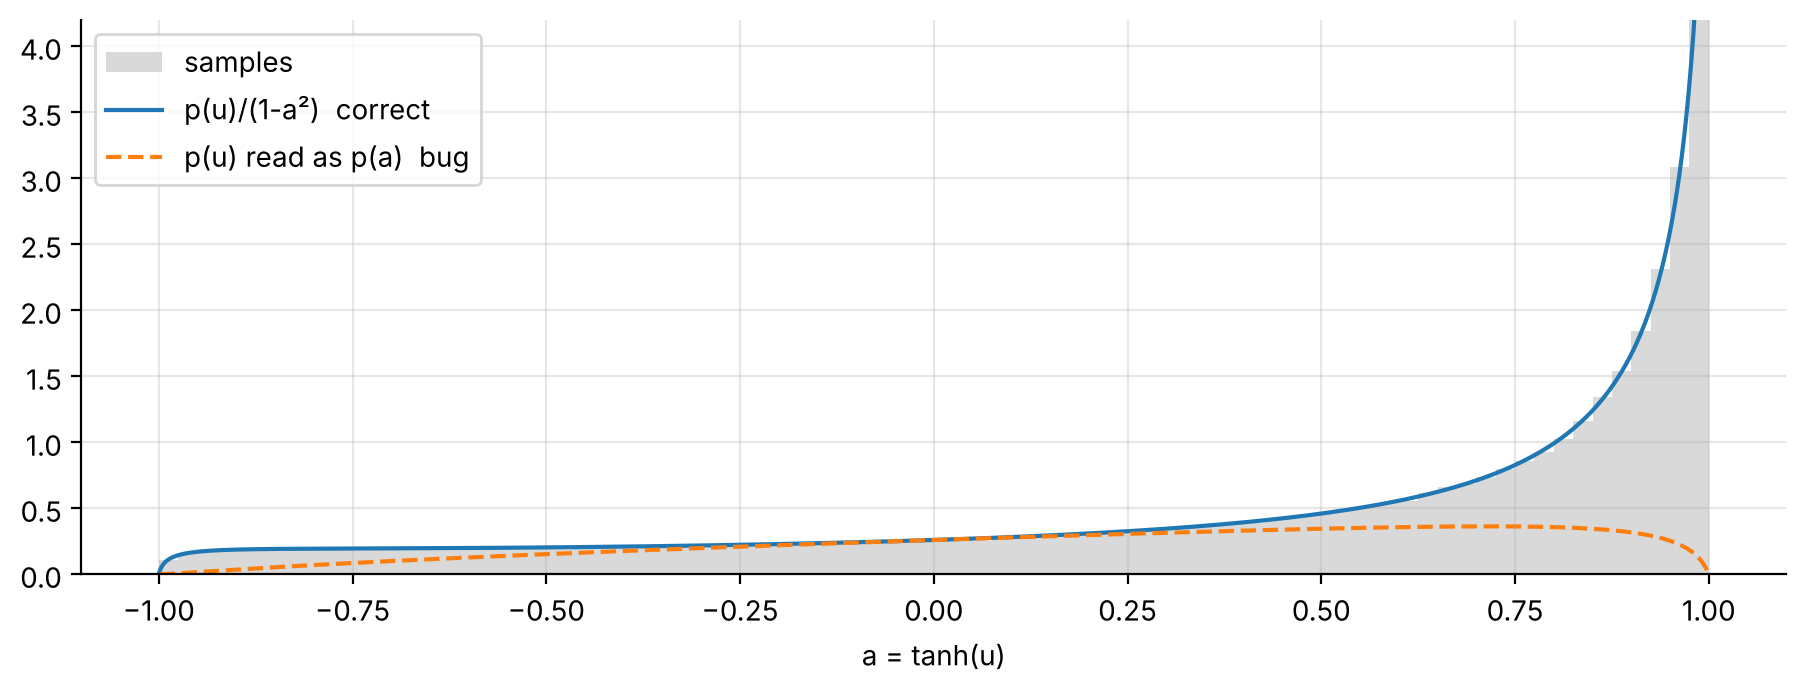

In [11]:
d = tanh_density()
print(f"true entropy of a          : {d['H_right']:.2f} nats")
print(f"Gaussian entropy (the bug) : {d['H_wrong']:.2f} nats")
print(f"share of actions |a|>0.99  : {100*d['frac_sat']:.1f} %")
plt.hist(d["a"], np.linspace(-1, 1, 81), density=True, color="0.85", label="samples")
plt.plot(d["grid"], d["p_right"], label="p(u)/(1-a²)  correct")
plt.plot(d["grid"], d["p_wrong"], "--", label="p(u) read as p(a)  bug")
plt.ylim(0, 4.2); plt.xlabel("a = tanh(u)"); plt.legend(); plt.show()

In code, write the correction in a numerically stable form. `log(1 - tanh(u)**2)` returns −inf once tanh rounds to 1.0:

```python
# wrong: no correction, so log-prob is the density of u
logp = Normal(mu, std).log_prob(u).sum(-1)
# wrong: right formula, but -inf for |u| > ~9 in float32
logp = Normal(mu, std).log_prob(u).sum(-1) - torch.log(1 - torch.tanh(u)**2).sum(-1)
# right: log(1 - tanh(u)^2) = 2 (log 2 - u - softplus(-2u))
logp = Normal(mu, std).log_prob(u).sum(-1) - (2*(math.log(2) - u - F.softplus(-2*u))).sum(-1)
```

## 6. The implementation

Everything below is a complete SAC, plus TD3 and DDPG through the same `Agent` class so that the comparison changes
only the algorithm. Networks are two hidden ReLU layers. The actor outputs mean and log-std, with log-std clamped to [−5, 2].

In [12]:
def mlp(i, o, h, n_layers=2):
    layers, d = [], i
    for _ in range(n_layers):
        layers += [nn.Linear(d, h), nn.ReLU()]; d = h
    layers.append(nn.Linear(d, o))
    return nn.Sequential(*layers)

LOG2 = math.log(2.0)

class GaussianActor(nn.Module):
    '''SAC actor: state -> (mean, log-std) of a Gaussian in u-space, action a = tanh(u).'''
    def __init__(self, od, ad, h):
        super().__init__()
        self.body = mlp(od, 2 * ad, h); self.ad = ad

    def forward(self, o, deterministic=False, tanh_correction=True):
        mu, log_std = self.body(o).split(self.ad, -1)
        log_std = log_std.clamp(-5.0, 2.0); std = log_std.exp()
        u = mu if deterministic else mu + std * torch.randn_like(mu)   # reparameterisation trick
        a = torch.tanh(u)
        logp = (-0.5 * ((u - mu) / std) ** 2 - log_std - 0.5 * math.log(2 * math.pi)).sum(-1)
        if tanh_correction:          # log |da/du| = log(1 - tanh(u)^2), written stably
            logp = logp - (2 * (LOG2 - u - F.softplus(-2 * u))).sum(-1)
        return a, logp, log_std

class DetActor(nn.Module):
    '''TD3 / DDPG actor: state -> action, deterministic.'''
    def __init__(self, od, ad, h):
        super().__init__(); self.body = mlp(od, ad, h)
    def forward(self, o):
        return torch.tanh(self.body(o))

class Critic(nn.Module):
    '''One or two Q networks Q(s, a).'''
    def __init__(self, od, ad, h, n_q=2):
        super().__init__()
        self.qs = nn.ModuleList([mlp(od + ad, 1, h) for _ in range(n_q)])
    def forward(self, o, a):
        x = torch.cat([o, a], -1)
        return torch.stack([q(x).squeeze(-1) for q in self.qs])

In [13]:
class Replay:
    def __init__(self, od, ad, size):
        self.o = torch.zeros(size, od); self.a = torch.zeros(size, ad); self.r = torch.zeros(size)
        self.o2 = torch.zeros(size, od); self.d = torch.zeros(size)
        self.size, self.ptr, self.full = size, 0, False
    def add(self, o, a, r, o2, d):
        n = len(o); idx = (self.ptr + np.arange(n)) % self.size
        self.o[idx] = torch.as_tensor(o); self.a[idx] = torch.as_tensor(a, dtype=torch.float32)
        self.r[idx] = torch.as_tensor(r); self.o2[idx] = torch.as_tensor(o2)
        self.d[idx] = torch.as_tensor(d, dtype=torch.float32)
        self.ptr = (self.ptr + n) % self.size; self.full |= self.ptr < n
    def __len__(self): return self.size if self.full else self.ptr
    def sample(self, b, g):
        i = torch.randint(len(self), (b,), generator=g)
        return self.o[i], self.a[i], self.r[i], self.o2[i], self.d[i]

The update step is the heart of the algorithm. Read it against the table in §3: the critic target uses the min of the
two *target* critics and a *fresh* action sampled at s′, the actor loss is `α·logπ − min Q`, and the α loss pushes
log-probabilities towards −target-entropy. The critics are frozen (`requires_grad_(False)`) during the actor step, so the
actor loss does not leak gradients into them.

In [14]:
DEFAULTS = dict(algo="sac", n_envs=1, steps=15000, start_steps=1000, hidden=64, batch=128,
                lr=1e-3, gamma=0.99, tau=0.005, buffer=100_000, utd=1,
                alpha="auto", target_entropy=None, alpha_lr=1e-3, init_alpha=1.0,
                twin=True, tanh_correction=True, timeout_bootstrap=True,
                expl_noise=0.1, target_noise=0.2, noise_clip=0.5, policy_delay=2,
                eval_every=1000, eval_eps=10, reward_scale=1.0)

class Agent:
    def __init__(self, od, ad, cfg, seed):
        torch.manual_seed(seed)
        self.cfg, self.ad = cfg, ad
        h, algo = cfg["hidden"], cfg["algo"]
        self.stochastic = algo == "sac"
        self.actor = GaussianActor(od, ad, h) if self.stochastic else DetActor(od, ad, h)
        self.actor_t = None if self.stochastic else DetActor(od, ad, h)
        n_q = 2 if (cfg["twin"] and algo != "ddpg") else 1
        self.critic, self.critic_t = Critic(od, ad, h, n_q), Critic(od, ad, h, n_q)
        self.critic_t.load_state_dict(self.critic.state_dict())
        if self.actor_t is not None: self.actor_t.load_state_dict(self.actor.state_dict())
        for p in self.critic_t.parameters(): p.requires_grad_(False)
        self.opt_a = torch.optim.Adam(self.actor.parameters(), lr=cfg["lr"])
        self.opt_c = torch.optim.Adam(self.critic.parameters(), lr=cfg["lr"])
        self.auto_alpha = cfg["alpha"] == "auto"
        self.target_ent = -float(ad) if cfg["target_entropy"] is None else cfg["target_entropy"]
        a0 = cfg["init_alpha"] if self.auto_alpha else max(float(cfg["alpha"]), 1e-12)
        self.log_alpha = torch.tensor(math.log(a0), requires_grad=self.auto_alpha)
        self.opt_al = torch.optim.Adam([self.log_alpha], lr=cfg["alpha_lr"])
        self.n_updates = 0
        self.g = torch.Generator().manual_seed(seed + 1000)

    @property
    def alpha(self):
        return self.log_alpha.exp().item() if (self.auto_alpha or self.cfg["alpha"] != 0) else 0.0

    @torch.no_grad()
    def act(self, o, deterministic=False):
        o = torch.as_tensor(o)
        if self.stochastic:
            return self.actor(o, deterministic, self.cfg["tanh_correction"])[0].numpy()
        a = self.actor(o)
        if not deterministic:
            a = (a + self.cfg["expl_noise"] * torch.randn(a.shape, generator=self.g)).clamp(-1, 1)
        return a.numpy()

    def q_value(self, o, a):
        with torch.no_grad():
            q = self.critic(torch.as_tensor(o), torch.as_tensor(a, dtype=torch.float32))
            return q.min(0).values.numpy()

    def update(self, batch):
        c = self.cfg; o, a, r, o2, d = batch
        al = self.alpha; info = {}
        with torch.no_grad():
            if self.stochastic:
                a2, logp2, _ = self.actor(o2, tanh_correction=c["tanh_correction"])
                qt = self.critic_t(o2, a2).min(0).values - al * logp2
            else:
                a2 = self.actor_t(o2)
                if c["algo"] == "td3":     # target-policy smoothing
                    eps = (c["target_noise"] * torch.randn(a2.shape, generator=self.g)
                           ).clamp(-c["noise_clip"], c["noise_clip"])
                    a2 = (a2 + eps).clamp(-1, 1)
                qt = self.critic_t(o2, a2).min(0).values
            y = c["reward_scale"] * r + c["gamma"] * (1 - d) * qt
        q = self.critic(o, a)
        lc = ((q - y) ** 2).mean(1).sum()
        self.opt_c.zero_grad(); lc.backward(); self.opt_c.step()
        info["critic_loss"] = lc.item() / q.shape[0]; info["q_mean"] = q.mean().item()
        self.n_updates += 1
        do_actor = c["algo"] != "td3" or self.n_updates % c["policy_delay"] == 0
        if do_actor:
            for p in self.critic.parameters(): p.requires_grad_(False)
            if self.stochastic:
                an, logp, log_std = self.actor(o, tanh_correction=c["tanh_correction"])
                qn = self.critic(o, an).min(0).values
                la = (al * logp - qn).mean()
                info.update(entropy=-logp.mean().item(), log_std=log_std.mean().item(),
                            sat=(an.abs() > 0.99).float().mean().item())
            else:
                an = self.actor(o)
                la = -self.critic(o, an)[0].mean()
                info.update(sat=(an.abs() > 0.99).float().mean().item())
            self.opt_a.zero_grad(); la.backward(); self.opt_a.step()
            for p in self.critic.parameters(): p.requires_grad_(True)
            if self.stochastic and self.auto_alpha:
                l_al = -(self.log_alpha * (logp.detach() + self.target_ent)).mean()
                self.opt_al.zero_grad(); l_al.backward(); self.opt_al.step()
            with torch.no_grad():
                for net, tgt in ((self.critic, self.critic_t), (self.actor, self.actor_t)):
                    if tgt is None: continue
                    for p, pt in zip(net.parameters(), tgt.parameters()):
                        pt.mul_(1 - c["tau"]).add_(c["tau"] * p)
        info["alpha"] = self.alpha
        return info

In [15]:
def train(env_name, cfg=None, seed=0, log_every=None, verbose=False):
    '''Generic off-policy loop.  cfg["algo"] in {"sac", "td3", "ddpg"}.'''
    c = dict(DEFAULTS); c.update(cfg or {})
    np.random.seed(seed); torch.manual_seed(seed)
    env = make_env(env_name, c["n_envs"], seed)
    ag = Agent(env.obs_dim, env.act_dim, c, seed)
    buf = Replay(env.obs_dim, env.act_dim, c["buffer"])
    rng = np.random.default_rng(seed + 7)
    o = env.reset(); steps = 0; hist = []; diag = []; last = {}
    t0 = time.time(); next_eval = 0; acc = {}
    while steps <= c["steps"]:
        if steps >= next_eval:
            ev = evaluate(ag, env_name, c["eval_eps"])
            ev.update(step=steps, time=time.time() - t0, **{k: float(np.mean(v)) for k, v in acc.items()})
            hist.append(ev); acc = {}; next_eval += c["eval_every"]
            if verbose: print(env_name, c["algo"], steps, round(ev["return"], 1), flush=True)
        if steps < c["start_steps"]:
            a = rng.uniform(-1, 1, (env.n, env.act_dim)).astype(np.float32)
        else:
            a = ag.act(o)
        o2, r, term, trunc, fo = env.step(a)
        done = term | (trunc & (not c["timeout_bootstrap"]))
        buf.add(o, a, r, fo, done)
        o = o2; steps += env.n
        if steps >= c["start_steps"]:
            for _ in range(c["utd"] * env.n):
                info = ag.update(buf.sample(c["batch"], ag.g))
                for k, v in info.items(): acc.setdefault(k, []).append(v)
    return ag, hist

def final_return(hist, k=3):
    return float(np.mean([h["return"] for h in hist[-k:]]))

### Three classic bugs, wrong beside right

```python
# 1. Time-outs treated as terminal.  The pendulum never terminates; it is only truncated at 200 steps.
done = term | trunc                    # wrong: the critic learns that step 200 has zero future value
done = term                            # right: bootstrap through time-outs (store final_obs as s')

# 2. Actor loss evaluated at the buffer action
q = critic(o, a_buffer).min(0).values  # wrong: no gradient reaches the actor at all
a_new, logp, _ = actor(o)              # right: sample a fresh action, so the gradient flows through it
q = critic(o, a_new).min(0).values

# 3. Gradient of the alpha loss flowing into the actor
l_alpha = -(log_alpha * (logp + target_ent)).mean()           # wrong: the actor is pushed by the alpha loss too
l_alpha = -(log_alpha * (logp.detach() + target_ent)).mean()  # right
```

Bug 1 and the missing tanh correction are both measured in the experiments below.

## 7. Running every experiment

One function trains a configuration and returns its learning curve, a soft-Q bias measurement (§8) and, on the
quadrotor, the hover metrics on 50 held-out start states. All runs go through a two-worker pool.
`fork` is Linux/macOS only; on Windows set `WORKERS = 1`.

In [16]:
def soft_q_bias(agent, env_name="pendulum", n=20, seed=777, t_max=50):
    '''Compare the critic's Q(s_t, a_t) with the realised *soft* return from that state,
    following the stochastic policy:  G_t = r_t + sum_k gamma^k (r_{t+k} - alpha log pi(a_{t+k}|s_{t+k})).
    Returns mean(Q - G) over t < t_max (the tail beyond the 200-step episode is ~0 once balanced).'''
    env = make_env(env_name, n, seed); o = env.reset(); g = agent.cfg["gamma"]
    al = agent.alpha; Qs, R, LP = [], [], []
    for t in range(env.T):
        with torch.no_grad():
            if agent.stochastic:
                a, lp, _ = agent.actor(torch.as_tensor(o), tanh_correction=agent.cfg["tanh_correction"])
                a, lp = a.numpy(), lp.numpy()
            else:
                a, lp = agent.act(o, True), np.zeros(n)
        Qs.append(agent.q_value(o, a)); LP.append(lp)
        o, r, *_ = env.step(a); R.append(r)
    R, LP, Qs = np.array(R), np.array(LP), np.array(Qs)
    # tail beyond the episode end: assume the last 10 steps' soft reward continues forever
    v_ss = (R[-10:] - al * LP[-10:]).mean(0)
    G = np.zeros_like(R); run = v_ss / (1 - g)
    for t in range(env.T - 1, -1, -1):
        bonus = -al * LP[t + 1] if t + 1 < env.T else 0.0
        run = R[t] + g * (bonus + run)
        G[t] = run
    return float((Qs[:t_max] - G[:t_max]).mean()), float(np.abs(G[:t_max]).mean())

In [17]:
PEND = dict(steps=12000, eval_every=1000)
QUAD = dict(steps=30000, n_envs=4, hidden=128, batch=256, lr=3e-4, alpha_lr=3e-4,
            start_steps=5000, eval_every=2500)
SEEDS = [0] if QUICK else [0, 1, 2]

JOBS = []
for name, extra in [("sac", {}), ("single", dict(twin=False)), ("notanh", dict(tanh_correction=False)),
                    ("timeout_term", dict(timeout_bootstrap=False)), ("td3", dict(algo="td3")),
                    ("ddpg", dict(algo="ddpg"))]:
    JOBS += [("pendulum", name, {**PEND, **extra}, s) for s in SEEDS]
for name, extra in [("sac", {}), ("single", dict(twin=False)), ("td3", dict(algo="td3")),
                    ("ddpg", dict(algo="ddpg"))]:
    JOBS += [("quad", name, {**QUAD, **extra}, s) for s in SEEDS]
JOBS += [("quad", f"alpha_{a}", {**QUAD, "alpha": a}, 0) for a in [0.0, 0.005, 0.05, 0.2, 1.0]]
JOBS += [("quad", "notanh", {**QUAD, "tanh_correction": False}, 0)]

def run(job):
    env, name, cfg, seed = job
    t0 = time.time()
    ag, hist = train(env, cfg, seed)
    out = dict(env=env, name=name, seed=seed, hist=hist, wall=time.time() - t0,
               final=final_return(hist), qbias=soft_q_bias(ag, env))
    if env == "quad":
        ev = evaluate(ag, "quad", 50, seed=999)
        out["eval"] = {k: ev[k] for k in ("return", "crash", "final_err_cm", "chatter")}
        if seed == 0:
            out["traj"] = np.array([a for _, a in evaluate(ag, "quad", 1, seed=4242, record=True)["traj"]])[:, 0]
    return out

WORKERS = 2 if sys.platform != "win32" else 1
t0 = time.time(); RES = {}
if WORKERS > 1:
    with mp.get_context("fork").Pool(WORKERS) as pool:
        for r in pool.imap_unordered(run, JOBS): RES[(r["env"], r["name"], r["seed"])] = r
else:
    for j in JOBS:
        r = run(j); RES[(r["env"], r["name"], r["seed"])] = r
print(f"{len(JOBS)} runs in {(time.time()-t0)/60:.1f} min")

def runs(env, name): return [RES[(env, name, s)] for s in SEEDS if (env, name, s) in RES]
def curves(env, name, key="return"):
    rs = runs(env, name)
    return (np.array([h["step"] for h in rs[0]["hist"]]),
            np.array([[h.get(key, np.nan) for h in r["hist"]] for r in rs]))
def last(r, key): return float(np.mean([h[key] for h in r["hist"][-3:]]))

36 runs in 19.3 min


### 7a. Pendulum: SAC, the bugs, and its deterministic relatives

We call the pendulum solved once the evaluation return passes −200 (a perfect policy scores about −145 from these start states).

In [18]:
print(f"{'config':14s} {'final return (3 seeds)':>30s} {'steps to -200':>14s} {'entropy':>8s} {'alpha':>7s} {'|a|>.99':>8s}")
for n in ["sac", "single", "notanh", "timeout_term", "td3", "ddpg"]:
    rs = runs("pendulum", n); x, Y = curves("pendulum", n)
    reach = [int(x[np.argmax(y >= -200)]) for y in Y if (y >= -200).any()]
    ent = np.mean([last(r, "entropy") for r in rs]) if n not in ("td3", "ddpg") else float("nan")
    alp = np.mean([last(r, "alpha") for r in rs]) if n not in ("td3", "ddpg") else float("nan")
    print(f"{n:14s} {np.mean([r['final'] for r in rs]):8.1f}  " + " ".join(f"{r['final']:7.1f}" for r in rs)
          + f" {np.mean(reach):12.0f}  {ent:8.2f} {alp:7.3f} {100*np.mean([last(r,'sat') for r in rs]):7.1f}%")

config                 final return (3 seeds)  steps to -200  entropy   alpha  |a|>.99
sac              -148.0   -148.7  -146.7  -148.4         4667     -0.99   0.122    13.3%
single           -147.9   -150.9  -142.8  -150.0         4333     -0.98   0.112    14.4%
notanh           -150.0   -148.9  -146.2  -154.9         6667      3.42   0.000    93.9%
timeout_term     -155.5   -172.6  -146.2  -147.7         6667     -1.00   0.153     9.3%
td3              -145.8   -146.8  -145.2  -145.4         7000       nan     nan    60.7%
ddpg             -148.0   -149.5  -146.3  -148.2         5000       nan     nan    40.5%


Read this table carefully, because the return column alone tells you almost nothing. **Every configuration solves the pendulum.**
SAC finishes at -148, TD3 at -146 and DDPG at -148.
Even the two buggy variants reach -150 and -156.
The pendulum is too easy to separate them on return.

The diagnostic columns are where the differences show.

* **Healthy SAC**: entropy settles at -0.99, exactly the target −dim(A) = −1, with α ≈ 0.12
  and 13 % of actions at the torque limit (swing-up genuinely needs full torque).
* **No tanh correction**: the "entropy" reads **3.42**, far above target. So the
  temperature update drives α to zero, log-std hits its upper clamp, and 94 % of
  actions sit at ±1: a bang-bang controller. It still solves the pendulum, because bang-bang is close to optimal for
  swing-up. It is about 6.7 k steps slower to reach −200
  (healthy: 4.7 k). §9 shows the same bug on the quadrotor, where bang-bang is not acceptable.
* **Time-out treated as terminal**: slower to solve (6.7 k steps), and its critic is
  biased low (§8).

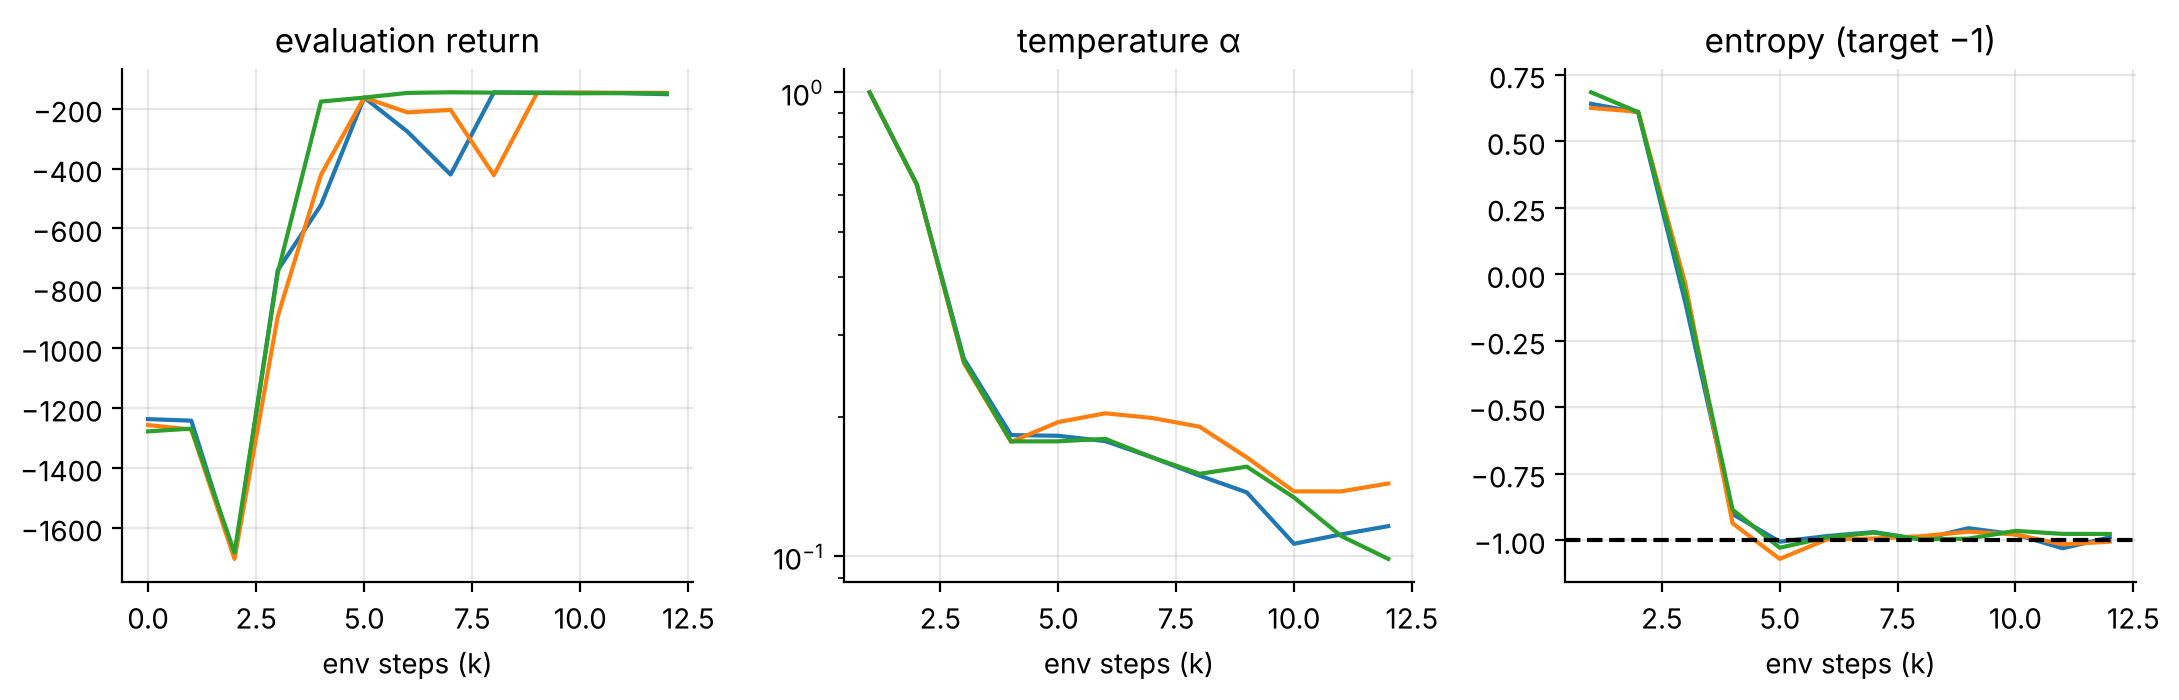

In [19]:
x, Y = curves("pendulum", "sac"); _, A = curves("pendulum", "sac", "alpha"); _, E = curves("pendulum", "sac", "entropy")
fig, ax = plt.subplots(1, 3)
for i in range(len(Y)):
    ax[0].plot(x/1e3, Y[i]); ax[1].semilogy(x[1:]/1e3, A[i, 1:]); ax[2].plot(x[1:]/1e3, E[i, 1:])
ax[2].axhline(-1, ls="--", c="k")
for a_, t in zip(ax, ["evaluation return", "temperature α", "entropy (target −1)"]):
    a_.set_title(t); a_.set_xlabel("env steps (k)")
plt.tight_layout(); plt.show()

This is what automatic temperature tuning looks like when it works. α starts at 1, so early behaviour is highly random.
As the critic learns which torques matter, the policy sharpens, the entropy falls to its target within ~5 k steps,
and α settles at the value that holds it there. You never chose that value; the dual update found it.

## 8. Clipped double-Q: deliberate pessimism

The actor climbs the critic's gradient, so any action whose value the critic **over**-estimates is an action the actor will
seek out. Taking the max over noisy estimates is biased upward (the DQN deep dive measured +1.74σ for a 15-action max). In
continuous control the actor plays the role of the max, and it is a very effective one. TD3 introduced the remedy that
SAC adopted: learn **two** critics and use the **smaller** in the target.

The minimum of two unbiased noisy estimates is biased *downward*, by about −0.56σ for independent errors. That is a deliberate
trade: under-estimating a good action costs a little; over-estimating a bad one sends the actor towards it.

In [20]:
rng = np.random.default_rng(0); e = rng.standard_normal((1_000_000, 2))
print(f"E[single noisy estimate]  = {e[:,0].mean():+.3f} σ")
print(f"E[min of two estimates]   = {e.min(1).mean():+.3f} σ")

E[single noisy estimate]  = +0.002 σ
E[min of two estimates]   = -0.563 σ


Now measure the real thing. For 20 evaluation episodes, record the critic's Q(s_t, a_t) along the trajectory and compare
it with the **soft return** actually realised from that point, $G_t = r_t + \sum_k \gamma^k (r_{t+k} - \alpha\log\pi)$.
That is what Q is supposed to estimate. We average over the first 50 steps of each episode.

In [21]:
print(f"{'':10s}{'SAC single Q':>14s}{'SAC twin Q':>12s}{'DDPG (1 Q)':>12s}{'TD3 (2 Q)':>12s}   typical |G|")
for env in ["pendulum", "quad"]:
    row = [np.mean([r["qbias"][0] for r in runs(env, n)]) for n in ["single", "sac", "ddpg", "td3"]]
    scale = np.mean([r["qbias"][1] for r in runs(env, "sac")])
    print(f"{env:10s}" + "".join(f"{v:+12.1f}  " for v in row) + f"   {scale:6.0f}")

            SAC single Q  SAC twin Q  DDPG (1 Q)   TD3 (2 Q)   typical |G|
pendulum          +5.0          -6.0         +12.9          -2.5         39
quad             -17.3         -25.2         -14.6         -50.0         82


On the **pendulum** the textbook picture appears. Both single-critic methods over-estimate: SAC with one Q by
+5.0 and DDPG by +12.9. Both twin-critic methods sit
slightly below the truth (SAC -6.0, TD3 -2.5).

On the **quadrotor** every critic is below the realised return, by 15–50 on a typical return of ~80. At 30 k steps the
long-horizon hover value is still propagating backwards through the Bellman backups, so all the critics are behind. The
twin critics remain the more pessimistic of each pair (SAC -25.2 vs -17.3;
TD3 -50.0 vs DDPG -14.6). Pessimism is cheap here: the actor
only needs the critic to *rank* actions correctly, not to price them. Quad hover error was
5.2 cm with twin critics vs 6.9 cm with one.

> **Take-away.** "Clipped double-Q removes over-estimation" is true where over-estimation exists. Measure the bias on
> your own task before attributing any improvement to it, as the DQN deep dive also found.

## 9. The quadrotor: SAC vs TD3 vs DDPG

Same networks (128 × 128), same buffer, same 30 k environment steps (4 parallel envs, one gradient step per environment
step), three seeds each. Hover error is the mean distance to the target over the last second of 50 held-out episodes;
chatter is the mean |Δu| per second, a proxy for motor wear and heat.

In [22]:
pd_ev = evaluate(pd_policy, "quad", 50, seed=999)
print(f"{'':14s}{'final return':>13s}{'steps to 190':>14s}{'hover err cm':>14s}{'chatter /s':>12s}{'crash':>7s}")
print(f"{'PD (model)':14s}{pd_ev['return']:13.1f}{'—':>14s}{pd_ev['final_err_cm']:14.2f}{pd_ev['chatter']:12.2f}{100*pd_ev['crash']:6.0f}%")
for n in ["sac", "single", "td3", "ddpg"]:
    rs = runs("quad", n); x, Y = curves("quad", n)
    reach = np.mean([x[np.argmax(y >= 190)] for y in Y if (y >= 190).any()])
    err = [r["eval"]["final_err_cm"] for r in rs]
    print(f"{n:14s}{np.mean([r['final'] for r in rs]):13.1f}{reach:14.0f}{np.mean(err):14.2f}"
          f"{np.mean([r['eval']['chatter'] for r in rs]):12.2f}{100*np.mean([r['eval']['crash'] for r in rs]):6.0f}%"
          f"   per-seed err: " + ", ".join(f"{v:.1f}" for v in err))

               final return  steps to 190  hover err cm  chatter /s  crash
PD (model)            216.9             —          0.02        0.09     0%
sac                   218.5         12500          5.17        1.18     0%   per-seed err: 1.1, 1.0, 13.5
single                212.8         15000          6.93        1.91     0%   per-seed err: 13.7, 5.1, 2.0
td3                   205.5         16667         12.79        4.07     0%   per-seed err: 16.0, 17.8, 4.6
ddpg                  195.4         15833         13.02       14.03     0%   per-seed err: 12.9, 8.8, 17.4


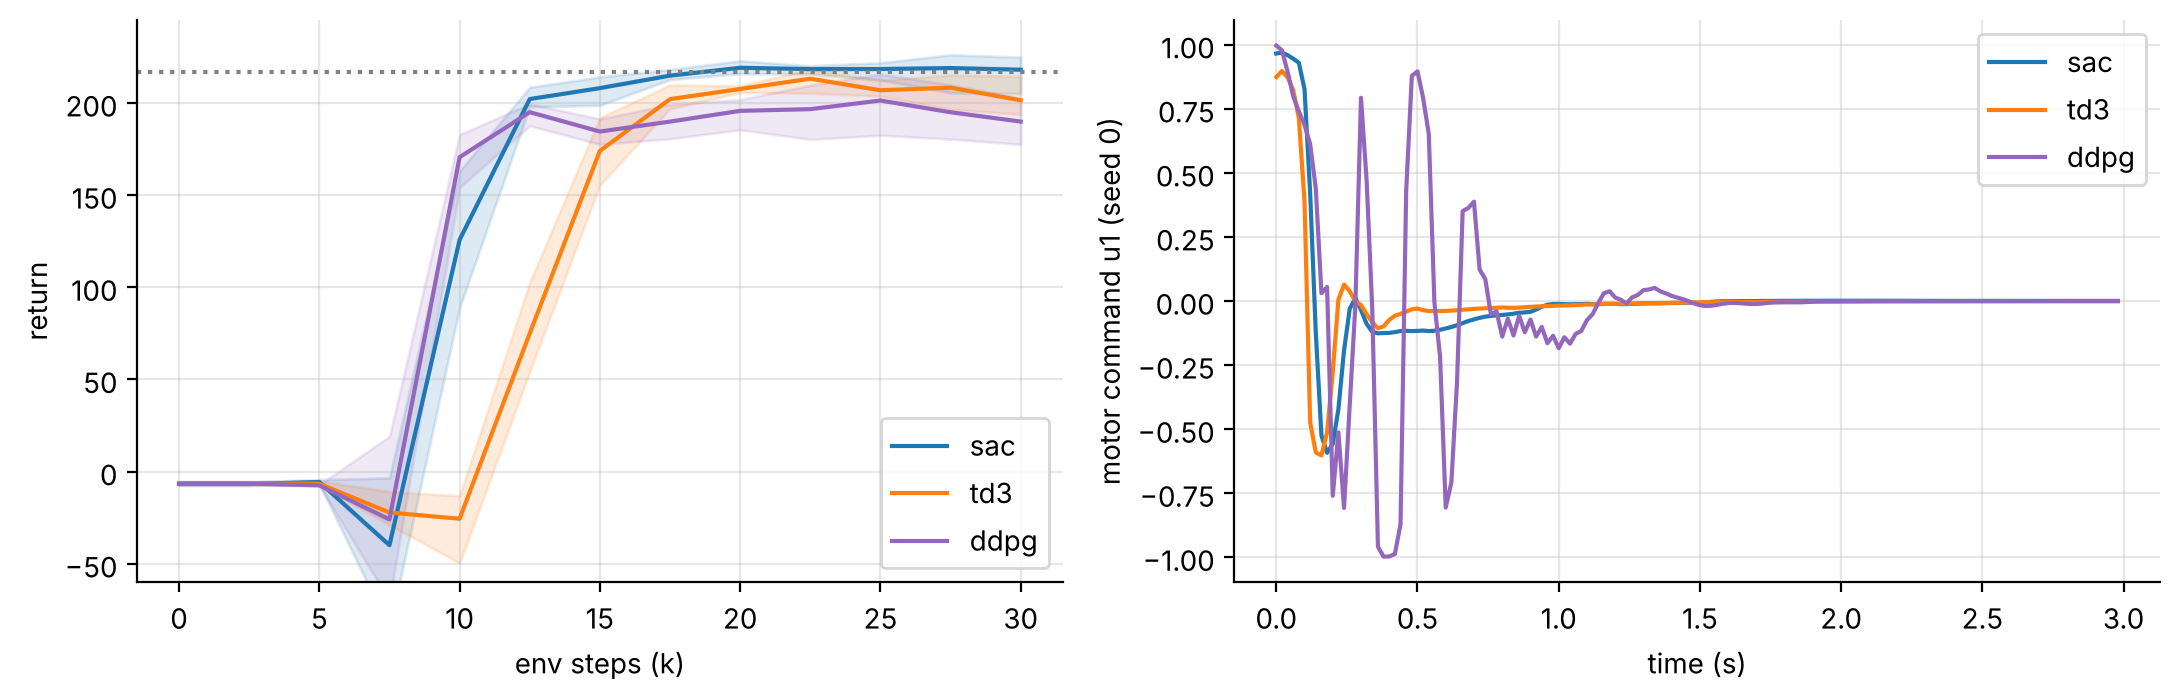

In [23]:
fig, ax = plt.subplots(1, 2)
for n, c in [("sac", "tab:blue"), ("td3", "tab:orange"), ("ddpg", "tab:purple")]:
    x, Y = curves("quad", n)
    ax[0].plot(x/1e3, Y.mean(0), c=c, label=n); ax[0].fill_between(x/1e3, Y.min(0), Y.max(0), color=c, alpha=0.15)
    ax[1].plot(np.arange(150)*0.02, RES[("quad", n, 0)]["traj"][:150, 0], c=c, label=n)
ax[0].axhline(pd_ev["return"], ls=":", c="gray"); ax[0].set_ylim(-60, 245)
ax[0].set_xlabel("env steps (k)"); ax[0].set_ylabel("return"); ax[0].legend()
ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("motor command u1 (seed 0)"); ax[1].legend()
plt.tight_layout(); plt.show()

* **Speed.** All three SAC seeds pass 190 at 12.5 k steps. TD3 and DDPG average
  16.7 k and 15.8 k.
* **Precision.** SAC hovers at 5.2 cm on average, against 12.8 cm for TD3 and
  13.0 cm for DDPG. Look at the per-seed column, though: two SAC seeds are at ~1 cm and one is at
  13 cm. With three seeds, report the spread, not just the mean.
* **Smoothness.** Chatter is 1.2/s for SAC, 4.1/s for TD3 and
  14.0/s for DDPG. In the trace, DDPG's motor slams between the limits during the approach. A deterministic
  actor trained with additive exploration noise has no reason to prefer smooth commands. SAC's entropy term keeps the
  action distribution wide where precision does not matter, so the critic sees many nearby actions and the mean action
  that comes out is smooth.
* **No crashes** for any method on held-out starts.
* **Honest caveat.** The model-based PD controller is still far more precise (0.02 cm). RL learns a
  very good controller without a model; it does not beat a well-tuned controller that has one.

### 9a. What the temperature actually does

Fix α at five values instead of tuning it (seed 0 each) and compare with automatic tuning.

In [24]:
print(f"{'alpha':>8s}{'return':>9s}{'hover err cm':>14s}{'chatter /s':>12s}{'entropy':>9s}{'|a|>.99':>9s}")
for key, name in [(a, f"alpha_{a}") for a in [0.0, 0.005, 0.05, 0.2, 1.0]] + [("auto", "sac")]:
    r = RES[("quad", name, 0)]
    print(f"{str(key):>8s}{r['final']:9.1f}{r['eval']['final_err_cm']:14.2f}{r['eval']['chatter']:12.2f}"
          f"{last(r,'entropy'):9.2f}{100*last(r,'sat'):8.1f}%")

   alpha   return  hover err cm  chatter /s  entropy  |a|>.99
     0.0    199.0          6.34        3.35   -15.37    26.5%
   0.005    217.3          3.63        2.35    -3.92    16.4%
    0.05    222.5          0.86        0.97    -0.87     4.5%
     0.2    224.6          0.89        0.52     0.23     1.1%
     1.0    209.4          6.09        0.24     0.73     0.5%
    auto    224.0          1.06        1.09    -1.98    10.9%


| α | what happens |
|---|---|
| 0 | no entropy bonus; the policy collapses (entropy -15.4 nats), 26 % of commands saturate, 6.3 cm, chatter 3.4/s |
| 0.005 | better, still 3.6 cm |
| 0.05 – 0.2 | the sweet spot: 0.9 – 0.9 cm, chatter falls from 1.0 to 0.5/s |
| 1.0 | too random: smoothest motors (0.24/s) but sloppy, 6.1 cm |
| **auto** | ends at α ≈ 0.02, 1.1 cm, 1.1/s, with **no tuning** |

The trade-off is **smoothness against precision**. More entropy gives smoother, more forgiving commands; too much and the policy
cannot commit to the fine corrections that hold position. Automatic tuning does not find the single best α. It finds a
good one without a sweep, which on a real robot is the difference between one training run and five.

## 10. Reading a SAC dashboard

Return curves are lagging and noisy. These four signals tell you *why* a run is behaving the way it is, usually long
before the return does. Compare the healthy quadrotor run with the one that has no tanh correction.

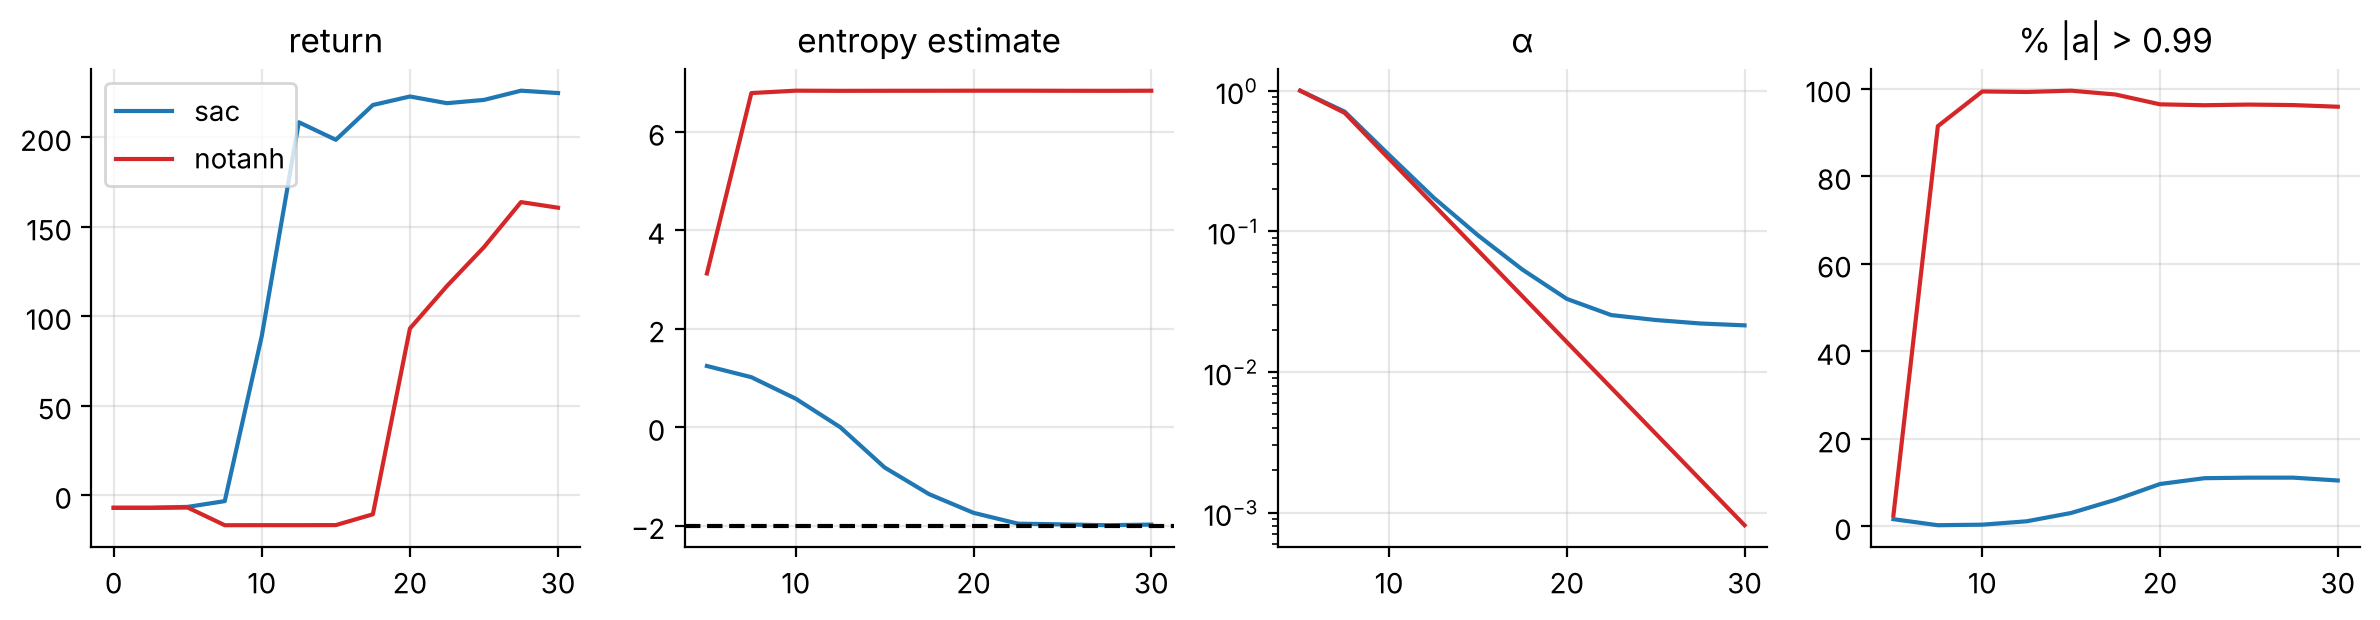

no tanh correction: return 154.4, hover err 18.9 cm, chatter 100.6/s, entropy estimate 6.84, saturated 96 %


In [25]:
fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
for name, c in [("sac", "tab:blue"), ("notanh", "tab:red")]:
    h = RES[("quad", name, 0)]["hist"]; x = np.array([e["step"] for e in h]) / 1e3
    g = lambda k: np.array([e.get(k, np.nan) for e in h])
    ax[0].plot(x, g("return"), c=c, label=name); ax[1].plot(x[1:], g("entropy")[1:], c=c)
    ax[2].semilogy(x[1:], g("alpha")[1:], c=c); ax[3].plot(x[1:], 100*g("sat")[1:], c=c)
ax[1].axhline(-2, ls="--", c="k"); ax[0].legend()
for a_, t in zip(ax, ["return", "entropy estimate", "α", "% |a| > 0.99"]): a_.set_title(t)
plt.tight_layout(); plt.show()
r = RES[("quad", "notanh", 0)]
print(f"no tanh correction: return {r['final']:.1f}, hover err {r['eval']['final_err_cm']:.1f} cm, "
      f"chatter {r['eval']['chatter']:.1f}/s, entropy estimate {last(r,'entropy'):.2f}, saturated {100*last(r,'sat'):.0f} %")

Without the correction, the entropy estimate jumps to 6.8 and stays there, far above the
target of −2. The temperature update concludes that the policy is too random and drives α towards zero. Nothing holds the
policy back, so it pushes its pre-squash mean far out and 96 % of motor commands sit at ±1.
The result is a bang-bang quadrotor with a chatter of 101/s, 18.9
cm off target, and return 154. The return curve only tells you that learning is slow. The entropy
and saturation panels tell you *why*, from the first evaluation after warm-up.

| symptom | likely cause | first check |
|---|---|---|
| entropy estimate flat and above target, α → 0 | missing tanh correction | log-prob formula |
| entropy collapses far below target, % saturated climbs | α too small or fixed at 0 | use auto-α; check target entropy |
| α grows without bound | target entropy unreachable (e.g. log-std clamp too tight) | log-std range vs target |
| Q values grow without bound, return falls | over-estimation or divergence | twin critics on? τ too large? lr too high? |
| Q far below realised return, slow learning | time-outs treated as terminal | `done = terminated` only |
| return fine, motor commands chatter | deterministic actor + noise (DDPG/TD3), or α too small | chatter metric; action trace |
| return improves then oscillates | learning rate, or critic loss exploding | critic loss curve |

## 11. Protocol: what to remember

1. **Sanity-check the environment first.** Run a do-nothing and a model-based policy. Bootstrap time-outs; terminate only on true terminals.
2. **Squash with tanh and correct the log-probability**, in the stable softplus form.
3. **Use the reparameterised actor gradient.** Sample a fresh action in the actor loss, never the buffer action.
4. **Two critics, take the min, Polyak-average the targets** (τ ≈ 0.005).
5. **Tune α automatically** with target entropy −dim(A). Treat a fixed α as a hyperparameter you must sweep.
6. **Evaluate the deterministic mean action** (tanh μ), and report precision and smoothness as well as return.
7. **Log entropy, α, saturation and Q every evaluation.** They diagnose problems before the return does.
8. **Ablate before you believe.** On the pendulum every variant, including two buggy ones, solved the task. Only a
   harder task and the diagnostics separated them.

## 12. Exercises

1. **Update-to-data ratio.** Run the quadrotor with `utd=2` and `utd=4`. Does SAC reach 190 in fewer environment steps? What
   happens to wall-clock time and to Q bias? (Background: REDQ, Chen et al. 2021.)
2. **Target entropy.** Auto-α targets −dim(A) = −2 on the quadrotor. Try −1, −4 and −8. Plot hover error and chatter against
   the target. Is there a target that beats every fixed α in §9a?
3. **The 13 cm seed.** One SAC quadrotor seed ends with a 13 cm hover error. Train it longer (60 k steps) and log its evaluation
   error over time. Is it stuck or still converging? What does its α trajectory look like compared with the 1 cm seeds?
4. **Stochastic evaluation.** Evaluate the trained policies with sampled actions instead of tanh(μ). How much do return,
   error and chatter change? What does that tell you about deploying the stochastic policy on hardware?
5. **Make over-estimation visible.** Over-estimation grows with action dimension and critic noise. Add 4 dummy action
   dimensions to the pendulum that do nothing, and rerun single-Q vs twin-Q SAC. Does the gap in §8 grow?
6. **Delayed actor for SAC.** TD3 updates the actor every second critic step. Add `policy_delay` to SAC. Does it help or hurt
   on the quadrotor?
7. **Motor-lag robustness.** Train SAC on the quadrotor with domain randomisation of the motor time constant (0–80 ms, as in the
   RL quadrotor lecture) and test at 80 ms. Does the entropy term make SAC more robust than PPO was without randomisation?
8. **Discrete SAC.** Adapt the actor to output a softmax over the DQN deep dive's 15-action menu, with an exact expectation in
   place of the reparameterised sample (Christodoulou, 2019). Compare with DQN on chatter and sample efficiency.

## 13. References

* Haarnoja, T., Zhou, A., Abbeel, P., Levine, S. (2018). Soft Actor-Critic: Off-Policy Maximum Entropy Deep Reinforcement
  Learning with a Stochastic Actor. *ICML 2018*, PMLR 80:1861–1870. arXiv:1801.01290.
* Haarnoja, T., Zhou, A., Hartikainen, K., et al. (2018). Soft Actor-Critic Algorithms and Applications. arXiv:1812.05905.
  (Automatic temperature tuning, target entropy −dim(A).)
* Haarnoja, T., Tang, H., Abbeel, P., Levine, S. (2017). Reinforcement Learning with Deep Energy-Based Policies. *ICML 2017*.
  (Soft Q-learning, the maximum-entropy framework.)
* Fujimoto, S., van Hoof, H., Meger, D. (2018). Addressing Function Approximation Error in Actor-Critic Methods (TD3).
  *ICML 2018*. arXiv:1802.09477.
* Lillicrap, T. P., et al. (2016). Continuous Control with Deep Reinforcement Learning (DDPG). *ICLR 2016*. arXiv:1509.02971.
* Kingma, D. P., Welling, M. (2014). Auto-Encoding Variational Bayes. *ICLR 2014*. (The reparameterisation trick.)
* Ziebart, B. D. (2010). *Modeling Purposeful Adaptive Behavior with the Principle of Maximum Causal Entropy*. PhD thesis, CMU.
* Chen, X., Wang, C., Zhou, Z., Ross, K. (2021). Randomized Ensembled Double Q-Learning (REDQ). *ICLR 2021*.
* Christodoulou, P. (2019). Soft Actor-Critic for Discrete Action Settings. arXiv:1910.07207.
* Haarnoja, T., Ha, S., Zhou, A., Tan, J., Tucker, G., Levine, S. (2019). Learning to Walk via Deep Reinforcement Learning.
  *RSS 2019*. (SAC on a real quadruped.)
* Raffin, A., et al. (2021). Stable-Baselines3: Reliable Reinforcement Learning Implementations. *JMLR* 22(268). (`SAC` reference implementation.)
* OpenAI Spinning Up: Soft Actor-Critic. https://spinningup.openai.com/en/latest/algorithms/sac.html

Generated by Claude and customized by

<div align="center">
<img src="https://raw.githubusercontent.com/dewdotninja/sharing-github/refs/heads/master/dewninja_logo50.jpg" alt="dewninja"/>
</div>
<div align="center">dew.ninja 2026</div>